Figure 3a

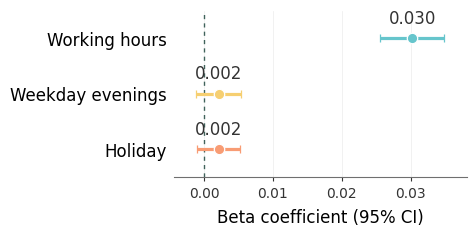

In [ ]:
# Dependencies: numpy, pandas, matplotlib.

from pathlib import Path

import matplotlib.pyplot as plt
plt.rcdefaults()
import numpy as np
import pandas as pd

RESULTS_DIR = Path("/data/time")

INPUT = RESULTS_DIR / "time.csv"

PALETTE = {
    "Working hours": "#66C5CC",
    "Weekday evenings": "#F6CF71",
    "Holiday": "#F89C74",
}
PERIOD_MAP = {
    "Workhours": "Working hours",
    "Evening": "Weekday evenings",
    "Holiday": "Holiday",
}
ORDER = ["Working hours", "Weekday evenings", "Holiday"]

coef = pd.read_csv(INPUT)
plot_df = (
    coef.loc[
        (coef["outcome"] == "existence_2020")
        & (coef["model"] == "Work/Evening/Holiday")
        & (coef["period"].isin(PERIOD_MAP)),
        ["period", "estimate", "std_error"],
    ]
    .assign(period=lambda x: x["period"].map(PERIOD_MAP))
    .set_index("period")
    .reindex(ORDER)
    .reset_index()
)

plot_df["ci_low"] = plot_df["estimate"] - 1.96 * plot_df["std_error"]
plot_df["ci_high"] = plot_df["estimate"] + 1.96 * plot_df["std_error"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "axes.linewidth": 0.8,
    "xtick.labelsize": 10,
    "ytick.labelsize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

fig, ax = plt.subplots(dpi=100, figsize=(4.65, 2.25), facecolor="white", constrained_layout=True)
ax.set_facecolor("white")
y_pos = np.array([0.72, 0.36, 0.00])

for y, row in zip(y_pos, plot_df.itertuples(index=False)):
    color = PALETTE[row.period]
    ax.errorbar(
        row.estimate,
        y,
        xerr=[[row.estimate - row.ci_low], [row.ci_high - row.estimate]],
        fmt="o",
        color=color,
        ecolor=color,
        elinewidth=2.3,
        capsize=3.2,
        capthick=1.5,
        markersize=7.5,
        markeredgecolor="white",
        markeredgewidth=0.9,
        zorder=3,
    )
    ax.annotate(
        f"{row.estimate:.3f}",
        xy=(row.estimate, y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=12,
        color="#333333",
    )

ax.axvline(0, color="#053229", linewidth=1.0, linestyle=(0, (3, 3)), alpha=0.75, zorder=2)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.5, alpha=0.75, zorder=0)
ax.grid(axis="y", visible=False)

ci_min = plot_df["ci_low"].min()
ci_max = plot_df["ci_high"].max()
span = ci_max - ci_min
pad = max(0.09 * span, 0.00003)
ax.set_xlim(ci_min - pad, ci_max + pad)
ax.set_ylim(-0.18, 0.90)
ax.set_yticks(y_pos, plot_df["period"])
ax.set_xlabel("Beta coefficient (95% CI)", labelpad=6)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#6f6f6f")
ax.tick_params(axis="y", length=0, pad=5)
ax.tick_params(axis="x", colors="#333333", length=3)

plt.show()


Figure 3b

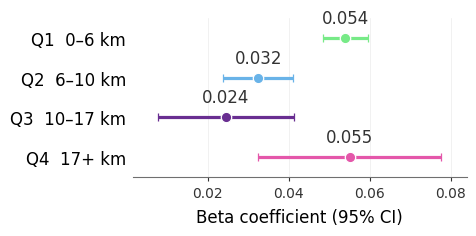

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
plt.rcdefaults()
import numpy as np
import pandas as pd

base_dir = Path("/data/dist")
csv_path = base_dir / "logit_2020_dist.csv"

df = pd.read_csv(csv_path)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.linewidth": 0.8,
    "xtick.labelsize": 10,
    "ytick.labelsize": 12,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

distance_order = ["q1", "q2", "q3", "q4"]
distance_labels = {
    "q1": "Q1  0–6 km",
    "q2": "Q2  6–10 km",
    "q3": "Q3  10–17 km",
    "q4": "Q4  17+ km",
}

COLORS = {
    "q1": "#77EA87",
    "q2": "#69B3E8",
    "q3": "#692E91",
    "q4": "#E457AA",
}

plot_df = df.copy()
plot_df["distance_bin"] = pd.Categorical(
    plot_df["distance_bin"], categories=distance_order, ordered=True
)
plot_df = plot_df.sort_values("distance_bin", ascending=True).reset_index(drop=True)
plot_df["label"] = plot_df["distance_bin"].astype(str).map(distance_labels)
plot_df["color"] = plot_df["distance_bin"].astype(str).map(COLORS)
plot_df["y"] = np.array([1.08, 0.72, 0.36, 0.00])

fig, ax = plt.subplots(dpi=100, figsize=(4.65, 2.25), facecolor="white", constrained_layout=True)
ax.set_facecolor("white")

ci_min = plot_df["conf_low"].min()
ci_max = plot_df["conf_high"].max()
span = ci_max - ci_min
pad = max(0.09 * span, 0.00003)

for row in plot_df.itertuples(index=False):
    ax.errorbar(
        row.estimate,
        row.y,
        xerr=[[row.estimate - row.conf_low], [row.conf_high - row.estimate]],
        fmt="o",
        color=row.color,
        ecolor=row.color,
        elinewidth=2.3,
        capsize=3.2,
        capthick=1.5,
        markersize=7.5,
        markeredgecolor="white",
        markeredgewidth=0.9,
        zorder=3,
    )
    ax.annotate(
        f"{row.estimate:.3f}",
        xy=(row.estimate, row.y),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=12,
        color="#333333",
    )

ax.axvline(0, color="#053229", linewidth=1.0, linestyle=(0, (3, 3)), alpha=0.75, zorder=2)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.5, alpha=0.75, zorder=0)
ax.grid(axis="y", visible=False)

ax.set_xlim(ci_min - pad, ci_max + pad)
ax.set_ylim(-0.18, 1.26)
ax.set_yticks(plot_df["y"], plot_df["label"])
ax.set_xlabel("Beta coefficient (95% CI)", labelpad=6)
ax.set_ylabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color("#6f6f6f")
ax.tick_params(axis="y", length=0, pad=5)
ax.tick_params(axis="x", colors="#333333", length=3)

plt.show()


Figure 3c

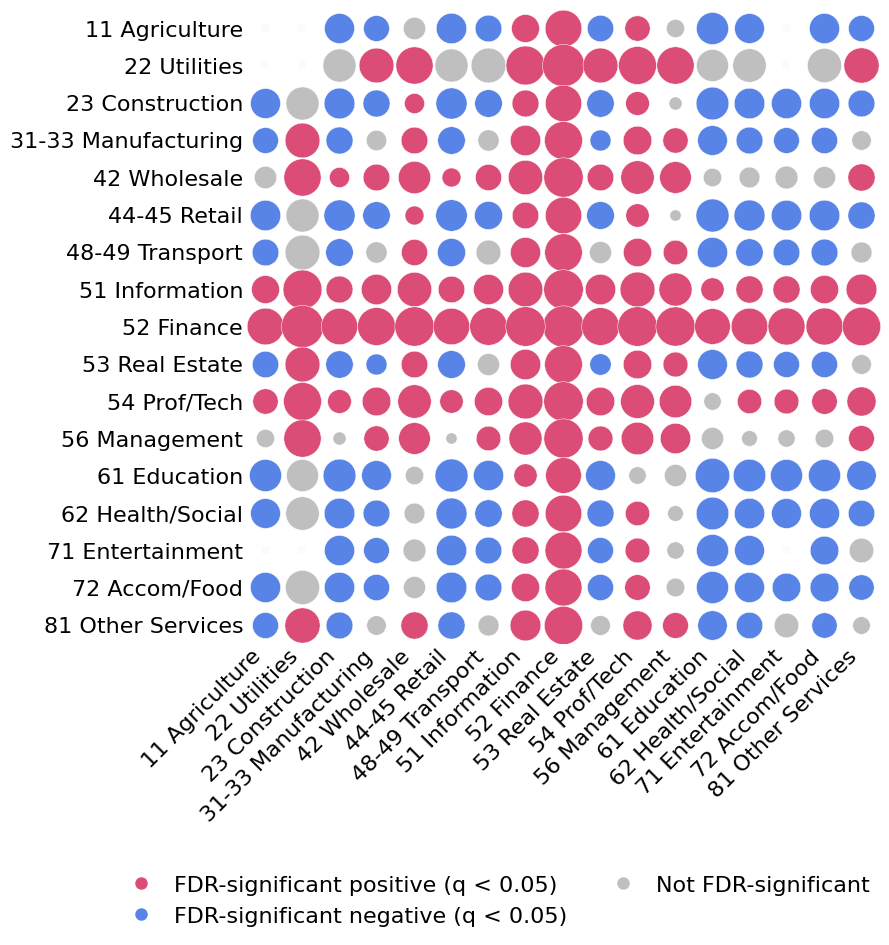

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcdefaults()
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

BASE_DIR = "/data/industry"
COEF_CSV = f"{BASE_DIR}/industry_coefficients.csv"
SPECIFICATION = "firm_count"
FDR_ALPHA = 0.05

naics_order = [
    "11", "22", "23", "31-33", "42", "44-45", "48-49",
    "51", "52", "53", "54", "56", "61", "62", "71", "72", "81"
]

naics_labels = {
    "11": "11 Agriculture",
    "21": "21 Mining",
    "22": "22 Utilities",
    "23": "23 Construction",
    "31-33": "31-33 Manufacturing",
    "42": "42 Wholesale",
    "44-45": "44-45 Retail",
    "48-49": "48-49 Transport",
    "51": "51 Information",
    "52": "52 Finance",
    "53": "53 Real Estate",
    "54": "54 Prof/Tech",
    "56": "56 Management",
    "61": "61 Education",
    "62": "62 Health/Social",
    "71": "71 Entertainment",
    "72": "72 Accom/Food",
    "81": "81 Other Services",
}

def prepare_coef(df):
    out = df.copy()
    parts = out["pair_type_naics"].astype(str).str.split("_", n=1, expand=True)
    out["ind_i"] = parts[0]
    out["ind_j"] = parts[1]
    out["sig"] = out["p_value_bh"] < FDR_ALPHA
    out["sig_pos"] = out["sig"] & (out["estimate"] > 0)
    out["sig_neg"] = out["sig"] & (out["estimate"] < 0)
    return out

def symmetrize(df):
    mirrored = df.copy()
    mirrored[["ind_i", "ind_j"]] = mirrored[["ind_j", "ind_i"]]
    return pd.concat([df, mirrored[df["ind_i"] != df["ind_j"]]], ignore_index=True)

def sig_color(beta, is_sig):
    if not is_sig:
        return "#bfbfbf"
    return "#DB4C77" if beta > 0 else "#5784E6"

def dot_size(beta, max_beta):
    if not np.isfinite(max_beta) or max_beta == 0:
        return 18
    magnitude = abs(beta) / max_beta
    return 18 + 900 * np.sqrt(magnitude)

def setup_matrix_axes(ax, title, order=naics_order):
    n_dim = len(order)
    axis_labels = [naics_labels[x] for x in order]

    ax.set_xticks(range(n_dim))
    ax.set_yticks(range(n_dim))
    ax.set_xticklabels(axis_labels, rotation=45, ha="right", fontsize=16)
    ax.set_yticklabels(axis_labels, fontsize=16)

    ax.set_xlim(-0.5, n_dim - 0.5)
    ax.set_ylim(n_dim - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.tick_params(length=0, pad=2)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.figure.patch.set_facecolor("white")
    ax.set_facecolor("white")

def draw_dot_matrix(df, title, order=naics_order):
    plot = df[df["ind_i"].isin(order) & df["ind_j"].isin(order)].copy()
    x_map = {v: i for i, v in enumerate(order)}
    y_map = {v: i for i, v in enumerate(order)}
    plot["x"] = plot["ind_j"].map(x_map)
    plot["y"] = plot["ind_i"].map(y_map)

    max_beta = plot["estimate"].abs().max()
    fig, ax = plt.subplots(dpi=100, figsize=(12, 9.5))

    for i in range(len(order)):
        for j in range(len(order)):
            ax.scatter(j, i, s=38, color="#fbfbfb", marker="s", linewidths=0, zorder=1)

    for _, row in plot.iterrows():
        beta = row["estimate"]
        ax.scatter(
            row["x"],
            row["y"],
            s=dot_size(beta, max_beta),
            c=sig_color(beta, row["sig"]),
            alpha=1.0,
            marker="o",
            edgecolors="#ffffff",
            linewidths=0.35,
            zorder=3,
        )

    setup_matrix_axes(ax, title, order)

    color_handles = [
        plt.Line2D([0], [0], marker="o", color="w", label="FDR-significant positive (q < 0.05)",
                   markerfacecolor="#DB4C77", markeredgecolor="#ffffff", markersize=10),
        plt.Line2D([0], [0], marker="o", color="w", label="FDR-significant negative (q < 0.05)",
                   markerfacecolor="#5784E6", markeredgecolor="#ffffff", markersize=10),
        plt.Line2D([0], [0], marker="o", color="w", label="Not FDR-significant",
                   markerfacecolor="#bfbfbf", markeredgecolor="#ffffff", markersize=10),
    ]
    fig.legend(
        handles=color_handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.01),
        ncol=2,
        frameon=False,
        fontsize=16,
        handletextpad=0.5,
        columnspacing=1.5,
        borderaxespad=0,
    )

    fig.tight_layout(rect=(0, 0.11, 1, 1))
    plt.show()
    plt.close(fig)

coef = pd.read_csv(COEF_CSV, dtype={"naics2_i": str, "naics2_j": str, "excluded_naics": str})
coef = coef.loc[coef["specification"].eq(SPECIFICATION)].copy()
coef = coef.rename(columns={"pair_type_naics2": "pair_type_naics"})
coef_m = symmetrize(prepare_coef(coef))
draw_dot_matrix(
    coef_m,
    "",
)
